# Beijing PM2.5 Air Pollution Prediction Using Machine Learning

This project analyzes Beijing air-quality data from multiple monitoring stations and applies machine learning techniques to predict PM2.5 concentration.

## A. Dataset Loading and Exploratory Data Analysis

### A1. Dataset Loading and Audit

In [60]:
import os

dataset_path = "../data"

print(os.listdir(dataset_path))

['beijing_combined.csv', 'PRSA_Data_Aotizhongxin_20130301-20170228.csv', 'PRSA_Data_Changping_20130301-20170228.csv', 'PRSA_Data_Dingling_20130301-20170228.csv', 'PRSA_Data_Dongsi_20130301-20170228.csv', 'PRSA_Data_Guanyuan_20130301-20170228.csv', 'PRSA_Data_Gucheng_20130301-20170228.csv', 'PRSA_Data_Huairou_20130301-20170228.csv', 'PRSA_Data_Nongzhanguan_20130301-20170228.csv', 'PRSA_Data_Shunyi_20130301-20170228.csv', 'PRSA_Data_Tiantan_20130301-20170228.csv', 'PRSA_Data_Wanliu_20130301-20170228.csv', 'PRSA_Data_Wanshouxigong_20130301-20170228.csv']


In [61]:
#Inspect all 12 files before combining them
import pandas as pd
import os

# Inspect the 12 original station files

files = [
    f for f in os.listdir(dataset_path)
    if f.endswith(".csv") and f != "beijing_combined.csv"
]

print("Number of station CSV files:", len(files))

print("\nFiles:")
for file in files:
    print(file)

print("\n--- Checking columns ---")

for file in files:
    df = pd.read_csv(os.path.join(dataset_path, file))
    print(f"\n{file}")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
    print("Column names:", list(df.columns))

Number of station CSV files: 12

Files:
PRSA_Data_Aotizhongxin_20130301-20170228.csv
PRSA_Data_Changping_20130301-20170228.csv
PRSA_Data_Dingling_20130301-20170228.csv
PRSA_Data_Dongsi_20130301-20170228.csv
PRSA_Data_Guanyuan_20130301-20170228.csv
PRSA_Data_Gucheng_20130301-20170228.csv
PRSA_Data_Huairou_20130301-20170228.csv
PRSA_Data_Nongzhanguan_20130301-20170228.csv
PRSA_Data_Shunyi_20130301-20170228.csv
PRSA_Data_Tiantan_20130301-20170228.csv
PRSA_Data_Wanliu_20130301-20170228.csv
PRSA_Data_Wanshouxigong_20130301-20170228.csv

--- Checking columns ---

PRSA_Data_Aotizhongxin_20130301-20170228.csv
Rows: 35064
Columns: 18
Column names: ['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station']

PRSA_Data_Changping_20130301-20170228.csv
Rows: 35064
Columns: 18
Column names: ['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'stat

In [62]:
#Combining the datasets
import pandas as pd
import os

dataframes = []

for file in files:
    file_path = os.path.join(dataset_path, file)
    df = pd.read_csv(file_path)
    dataframes.append(df)

# Combine all 12 station datasets
beijing_combined = pd.concat(dataframes, ignore_index=True)

print("Combined dataset shape:", beijing_combined.shape)
print("\nFirst 5 rows:")
display(beijing_combined.head())

Combined dataset shape: (420768, 18)

First 5 rows:


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [63]:
display(beijing_combined.tail())

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
420763,35060,2017,2,28,19,11.0,32.0,3.0,24.0,400.0,72.0,12.5,1013.5,-16.2,0.0,NW,2.4,Wanshouxigong
420764,35061,2017,2,28,20,13.0,32.0,3.0,41.0,500.0,50.0,11.6,1013.6,-15.1,0.0,WNW,0.9,Wanshouxigong
420765,35062,2017,2,28,21,14.0,28.0,4.0,38.0,500.0,54.0,10.8,1014.2,-13.3,0.0,NW,1.1,Wanshouxigong
420766,35063,2017,2,28,22,12.0,23.0,4.0,30.0,400.0,59.0,10.5,1014.4,-12.9,0.0,NNW,1.2,Wanshouxigong
420767,35064,2017,2,28,23,13.0,19.0,4.0,38.0,600.0,49.0,8.6,1014.1,-15.9,0.0,NNE,1.3,Wanshouxigong


In [64]:
#Saving the combined datasets
combined_file_path = os.path.join(
    dataset_path,
    "beijing_combined.csv"
)

beijing_combined.to_csv(combined_file_path, index=False)

print("Combined dataset saved successfully!")
print(combined_file_path)

Combined dataset saved successfully!
../data\beijing_combined.csv


In [65]:
#Basic dataset information
print("Shape of dataset:")
print(beijing_combined.shape)

print("\nColumn names:")
print(beijing_combined.columns.tolist())

print("\nData types:")
print(beijing_combined.dtypes)

Shape of dataset:
(420768, 18)

Column names:
['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station']

Data types:
No           int64
year         int64
month        int64
day          int64
hour         int64
PM2.5      float64
PM10       float64
SO2        float64
NO2        float64
CO         float64
O3         float64
TEMP       float64
PRES       float64
DEWP       float64
RAIN       float64
wd          object
WSPM       float64
station     object
dtype: object


In [66]:
#Statistical overview
beijing_combined.describe()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,412029.000000,414319.000000,411747.000000,408652.000000,400067.000000,407491.000000,420370.000000,420375.000000,420365.000000,420378.000000,420450.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,79.793428,104.602618,15.830835,50.638586,1230.766454,57.372271,13.538976,1010.746982,2.490822,0.064476,1.729711
std,10122.116943,1.177198,3.448707,8.800102,6.922195,80.822391,91.772426,21.650603,35.127912,1160.182716,56.661607,11.436139,10.474055,13.793847,0.821004,1.246386
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,20.000000,36.000000,3.000000,23.000000,500.000000,11.000000,3.100000,1002.300000,-8.900000,0.000000,0.900000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,45.000000,14.500000,1010.400000,3.100000,0.000000,1.400000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000,23.300000,1019.000000,15.100000,0.000000,2.200000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,999.000000,999.000000,500.000000,290.000000,10000.000000,1071.000000,41.600000,1042.800000,29.100000,72.500000,13.200000


In [67]:
#Missing values
print("Missing values in each column:")
print(beijing_combined.isnull().sum())

Missing values in each column:
No             0
year           0
month          0
day            0
hour           0
PM2.5       8739
PM10        6449
SO2         9021
NO2        12116
CO         20701
O3         13277
TEMP         398
PRES         393
DEWP         403
RAIN         390
wd          1822
WSPM         318
station        0
dtype: int64


In [68]:
print("Total rows:", len(beijing_combined))
print("Missing PM2.5:", beijing_combined['PM2.5'].isnull().sum())

pm25_missing_percentage = (
    beijing_combined['PM2.5'].isnull().sum()
    / len(beijing_combined)
) * 100

print("Missing PM2.5 percentage:", pm25_missing_percentage)

Total rows: 420768
Missing PM2.5: 8739
Missing PM2.5 percentage: 2.0769164955509924


In [69]:
#Duplicate values
print("Number of duplicate rows:")
print(beijing_combined.duplicated().sum())

Number of duplicate rows:
0


In [70]:
#Unique values in the categorical columns
print("Unique values in 'wd':")
print(beijing_combined["wd"].unique())

print("\nNumber of unique wind-direction values:")
print(beijing_combined["wd"].nunique())

print("\nUnique stations:")
print(beijing_combined["station"].unique())

print("\nNumber of unique stations:")
print(beijing_combined["station"].nunique())

Unique values in 'wd':
['NNW' 'N' 'NW' 'NNE' 'ENE' 'E' 'NE' 'W' 'SSW' 'WSW' 'SE' 'WNW' 'SSE'
 'ESE' 'S' 'SW' nan]

Number of unique wind-direction values:
16

Unique stations:
['Aotizhongxin' 'Changping' 'Dingling' 'Dongsi' 'Guanyuan' 'Gucheng'
 'Huairou' 'Nongzhanguan' 'Shunyi' 'Tiantan' 'Wanliu' 'Wanshouxigong']

Number of unique stations:
12


In [71]:
# Check how many rows each station has
print(beijing_combined['station'].value_counts())

station
Aotizhongxin     35064
Changping        35064
Dingling         35064
Dongsi           35064
Guanyuan         35064
Gucheng          35064
Huairou          35064
Nongzhanguan     35064
Shunyi           35064
Tiantan          35064
Wanliu           35064
Wanshouxigong    35064
Name: count, dtype: int64


In [72]:
numerical_columns = beijing_combined.select_dtypes(
    include="number"
).columns

print("Numerical columns:")
print(numerical_columns.tolist())

print("\nNumber of numerical columns:", len(numerical_columns))

Numerical columns:
['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']

Number of numerical columns: 16


### A2. EDA Visualisations

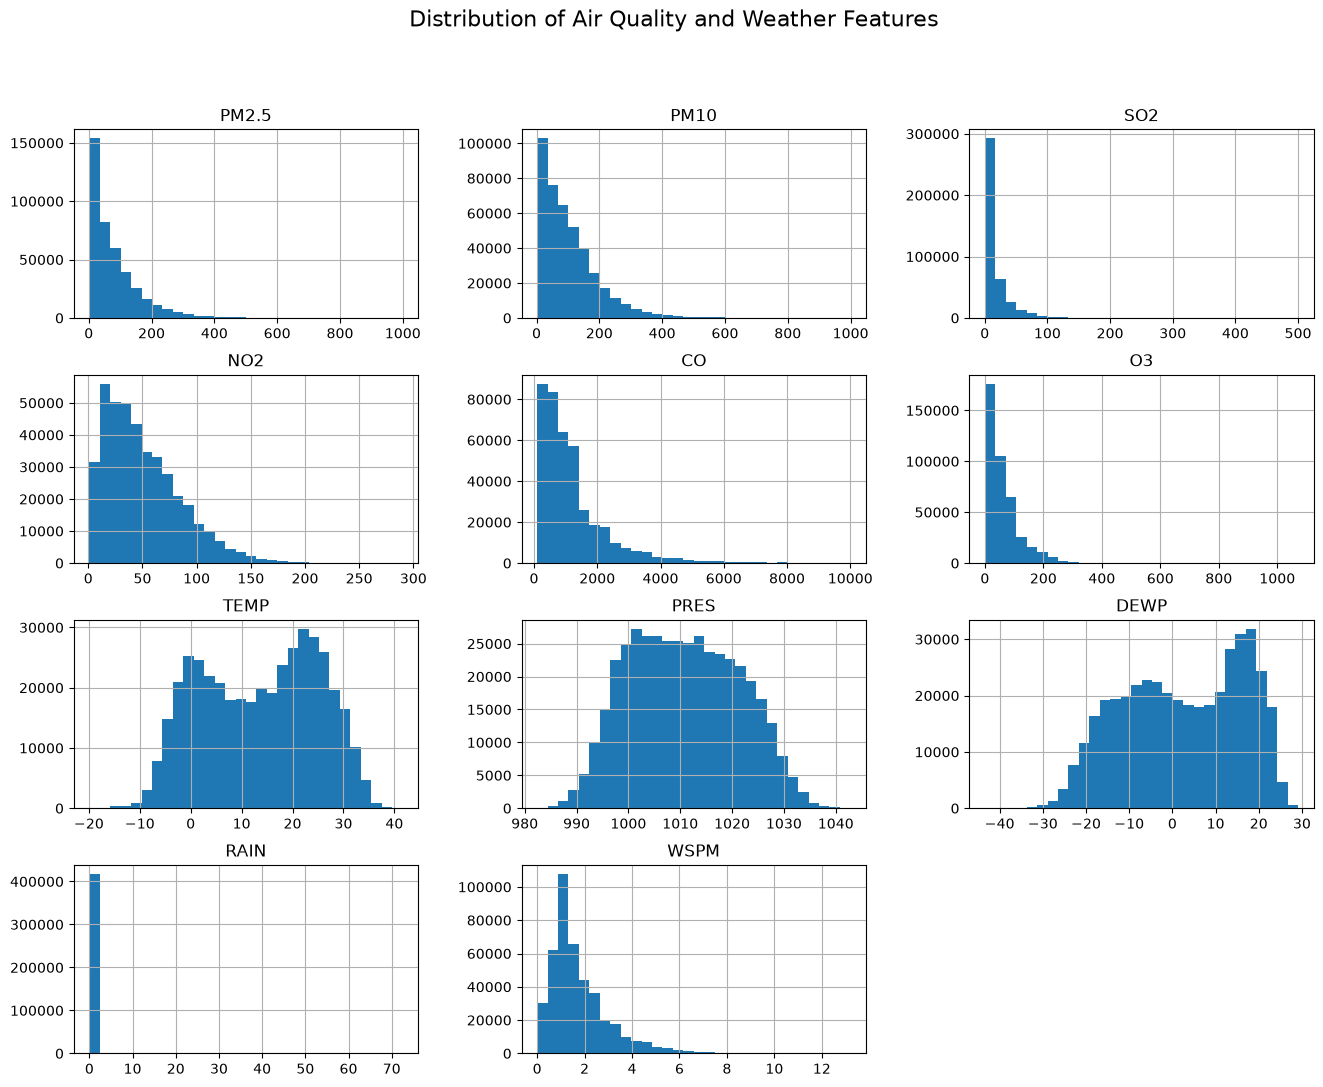

In [73]:
import matplotlib.pyplot as plt

eda_columns = [
    'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3',
    'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM'
]

beijing_combined[eda_columns].hist(
    figsize=(16, 12),
    bins=30
)

plt.suptitle("Distribution of Air Quality and Weather Features", fontsize=16)
plt.show()

### Insight Commentary

The distributions of the air-quality and weather features vary considerably. Most pollutant concentrations are right-skewed, with many observations at lower values and fewer observations at higher values. The weather variables show different distribution patterns, indicating that the features have different ranges and characteristics.

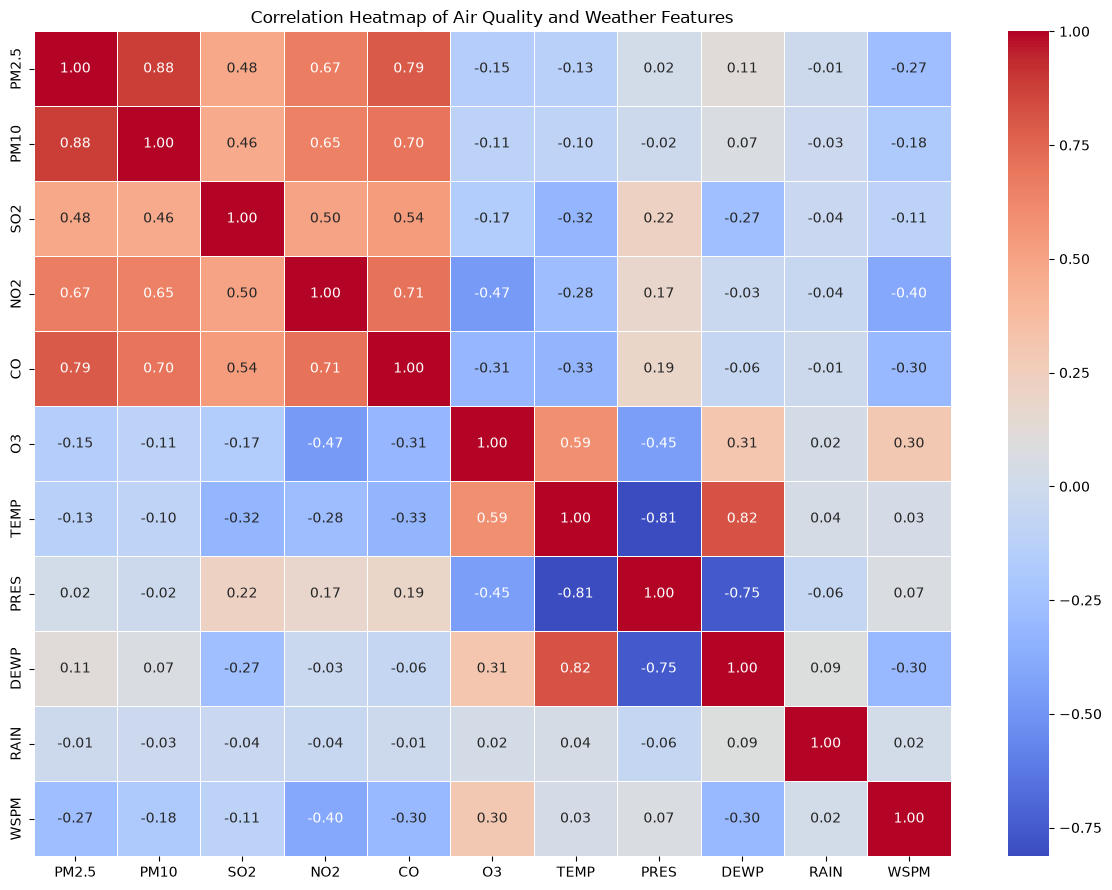

In [74]:
#Heat Map
import matplotlib.pyplot as plt
import seaborn as sns

correlation = beijing_combined[eda_columns].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Air Quality and Weather Features")
plt.tight_layout()
plt.show()

### Insight Commentary

The correlation heatmap shows that PM2.5 has a strong positive correlation with PM10 (0.88) and CO (0.79). It also shows a moderately positive correlation with NO2 (0.67) and SO2 (0.48). O3 (-0.15), TEMP (-0.13), and WSPM (-0.27) have relatively weak negative correlations with PM2.5, while PRES (0.02) and RAIN (-0.01) show almost no linear correlation. These correlations indicate that PM10, CO, and NO2 may be useful predictors of PM2.5.

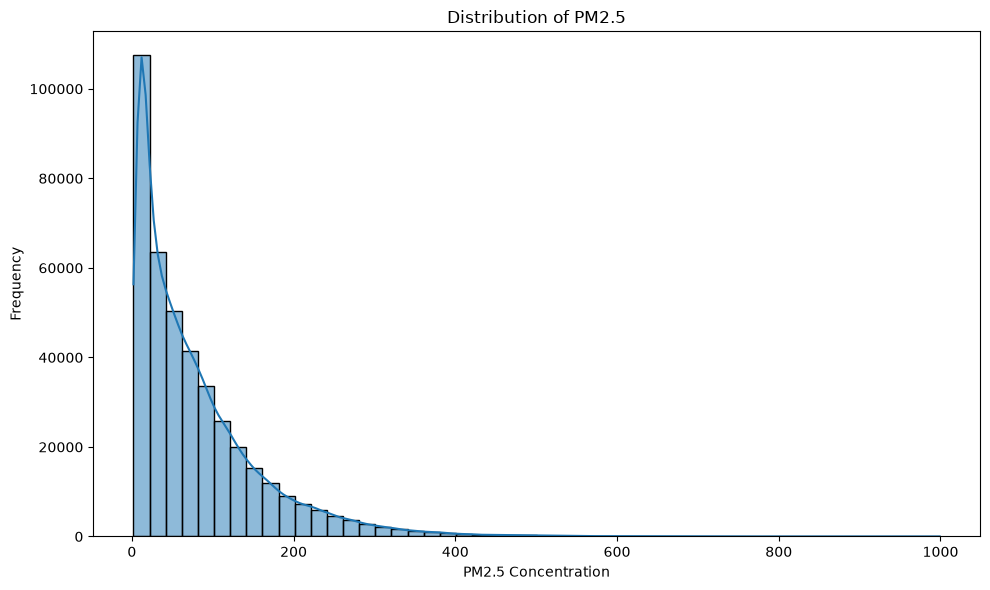

In [75]:
#Target Distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    data=beijing_combined,
    x='PM2.5',
    bins=50,
    kde=True
)

plt.title("Distribution of PM2.5")
plt.xlabel("PM2.5 Concentration")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Insight Commentary

The PM2.5 distribution is strongly right-skewed, with most observations concentrated at lower concentration values and fewer observations at higher concentrations. The long right tail indicates the presence of occasional high-pollution observations.

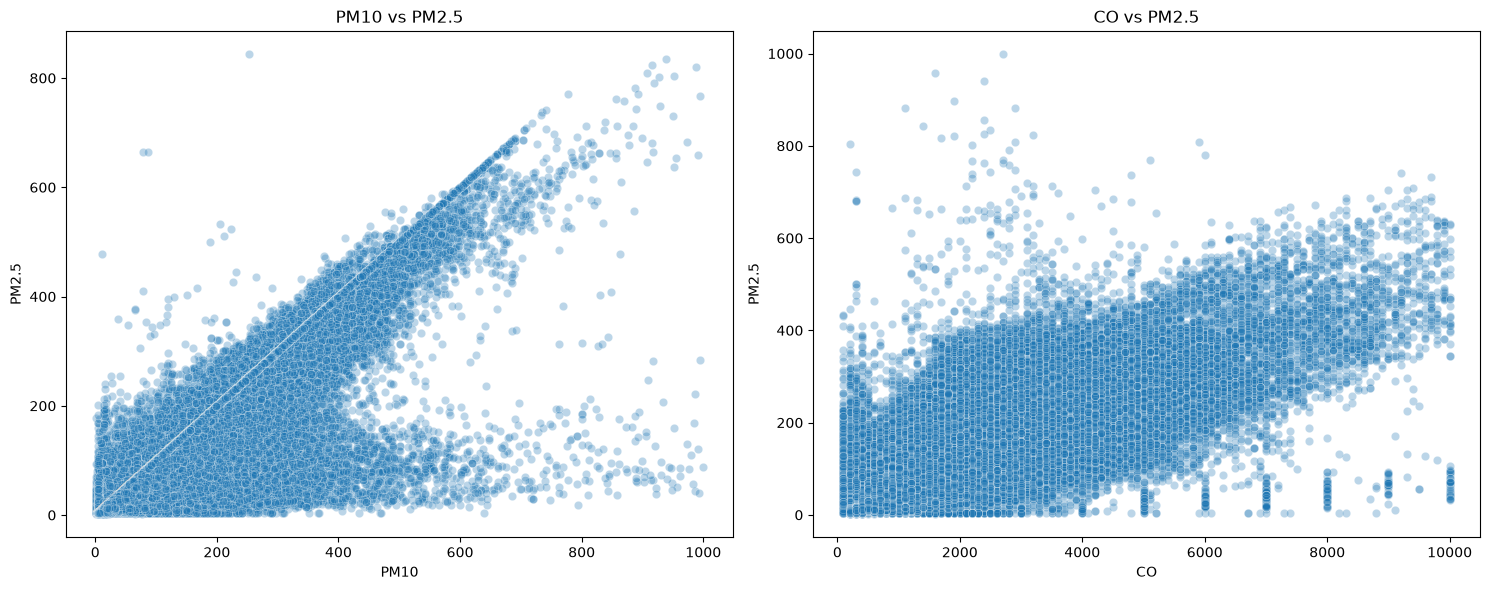

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# PM10 vs PM2.5
sns.scatterplot(
    data=beijing_combined,
    x='PM10',
    y='PM2.5',
    alpha=0.3,
    ax=axes[0]
)

axes[0].set_title("PM10 vs PM2.5")
axes[0].set_xlabel("PM10")
axes[0].set_ylabel("PM2.5")

# CO vs PM2.5
sns.scatterplot(
    data=beijing_combined,
    x='CO',
    y='PM2.5',
    alpha=0.3,
    ax=axes[1]
)

axes[1].set_title("CO vs PM2.5")
axes[1].set_xlabel("CO")
axes[1].set_ylabel("PM2.5")

plt.tight_layout()
plt.show()

### Insight Commentary

The scatter plot shows a strong positive relationship between PM10 and PM2.5. As PM10 concentration increases, PM2.5 generally increases as well. The points become widely distributed at higher concentrations, indicating some variability and the presence of outlying observations.

### Insight Commentary

The scatter plot shows a positive relationship between CO and PM2.5. Higher CO concentrations are generally associated with higher PM2.5 concentrations, although the points are more widely scattered compared with the PM10 relationship. This suggests that CO may be a useful predictor of PM2.5, but the relationship has greater variability.

## B. Preprocessing and Feature Engineering

### B1. Data Cleaning

In [77]:
# Checking outliers using the IQR method

Q1 = beijing_combined[eda_columns].quantile(0.25)
Q3 = beijing_combined[eda_columns].quantile(0.75)

IQR = Q3 - Q1

outlier_counts = (
    (beijing_combined[eda_columns] < (Q1 - 1.5 * IQR)) |
    (beijing_combined[eda_columns] > (Q3 + 1.5 * IQR))
).sum()

print("Number of outliers in each feature:")
print(outlier_counts)

Number of outliers in each feature:
PM2.5    19142
PM10     14658
SO2      35566
NO2       7021
CO       28054
O3       16599
TEMP         0
PRES         0
DEWP         0
RAIN     16520
WSPM     23079
dtype: int64


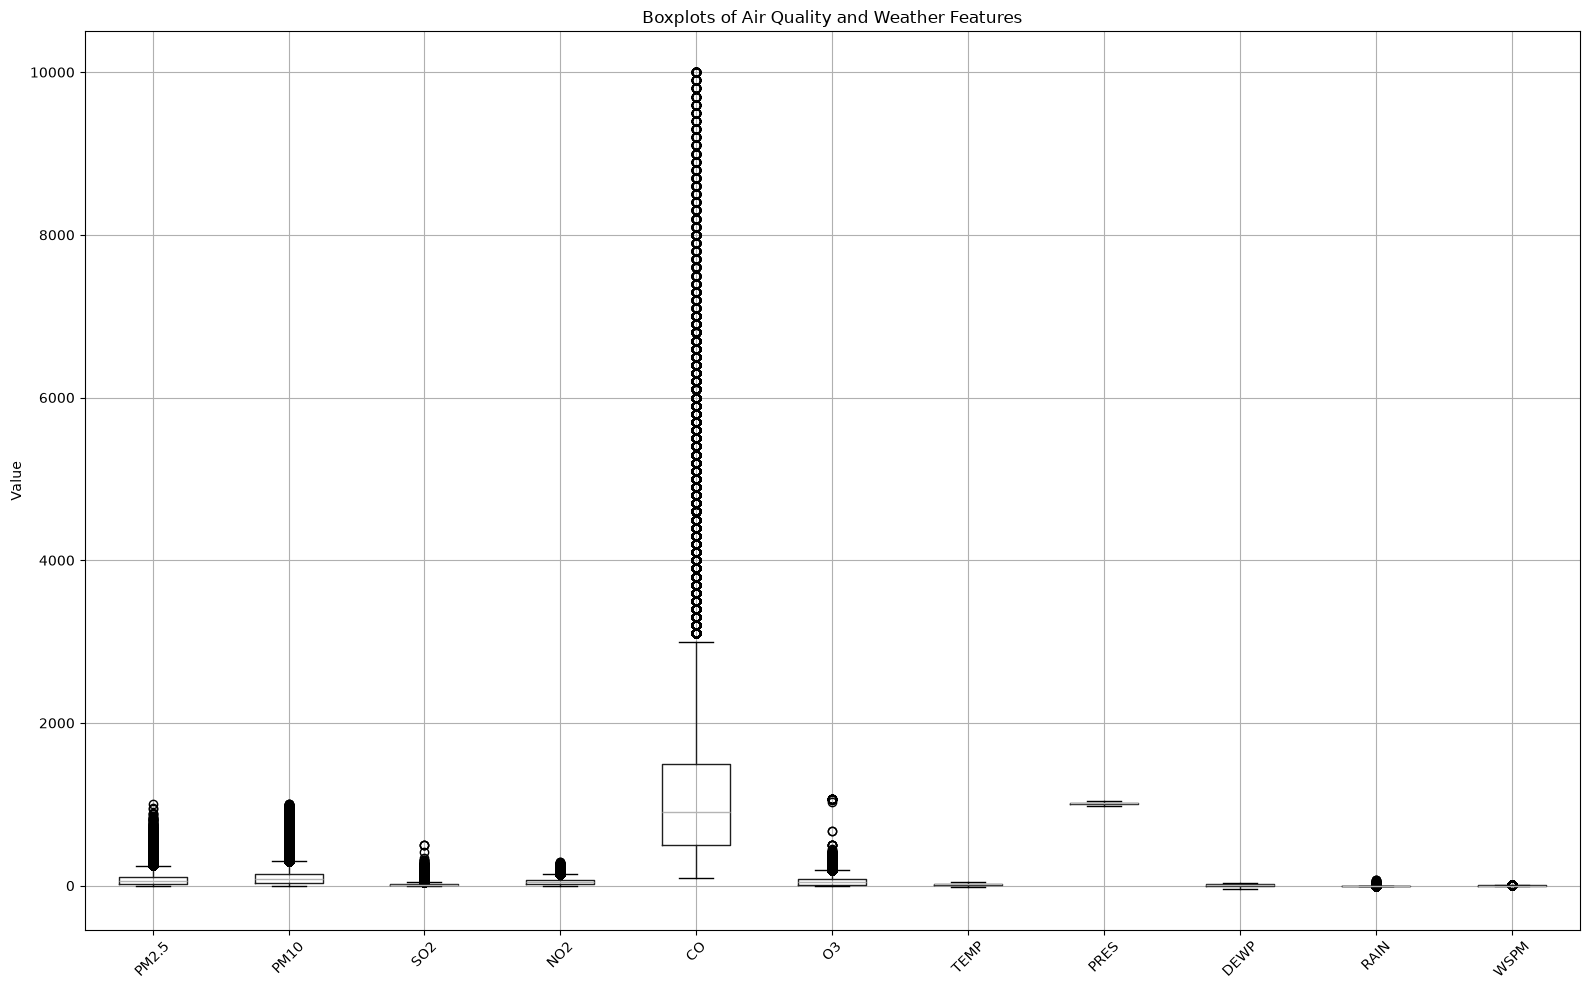

In [78]:
#Boxplot
plt.figure(figsize=(16, 10))

beijing_combined[eda_columns].boxplot()

plt.title("Boxplots of Air Quality and Weather Features")
plt.xticks(rotation=45)
plt.ylabel("Value")

plt.tight_layout()
plt.show()

### Insight Commentary

The boxplots show that several air-quality features contain a substantial number of values outside the IQR-based whiskers. This is particularly noticeable for PM2.5, PM10, SO2, CO, O3, RAIN, and WSPM. These observations are treated as potential outliers during preprocessing rather than being automatically removed, because extreme pollution and weather measurements may represent genuine environmental conditions.

### Outlier Treatment

The IQR method flagged many outliers, but no negative (impossible) values were found.
Outliers were kept because extreme pollution and weather events are genuine, and
removing them would hurt prediction of high-pollution periods.

In [79]:
# Check for physically impossible values

print("Negative PM2.5:", (beijing_combined['PM2.5'] < 0).sum())
print("Negative PM10:", (beijing_combined['PM10'] < 0).sum())
print("Negative SO2:", (beijing_combined['SO2'] < 0).sum())
print("Negative NO2:", (beijing_combined['NO2'] < 0).sum())
print("Negative CO:", (beijing_combined['CO'] < 0).sum())
print("Negative O3:", (beijing_combined['O3'] < 0).sum())
print("Negative RAIN:", (beijing_combined['RAIN'] < 0).sum())
print("Negative WSPM:", (beijing_combined['WSPM'] < 0).sum())

Negative PM2.5: 0
Negative PM10: 0
Negative SO2: 0
Negative NO2: 0
Negative CO: 0
Negative O3: 0
Negative RAIN: 0
Negative WSPM: 0


In [80]:
# Check missing values before treatment

missing_values = beijing_combined.isnull().sum()

print("Missing values in each column:")
print(missing_values[missing_values > 0])

Missing values in each column:
PM2.5     8739
PM10      6449
SO2       9021
NO2      12116
CO       20701
O3       13277
TEMP       398
PRES       393
DEWP       403
RAIN       390
wd        1822
WSPM       318
dtype: int64


In [81]:
# Handle missing values

# Remove rows where the target (PM2.5) is missing
beijing_cleaned = beijing_combined.dropna(subset=['PM2.5']).copy()

# Numerical feature columns
numeric_features = [
    'PM10', 'SO2', 'NO2', 'CO', 'O3',
    'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM'
]

# Fill missing numerical features with their median
for col in numeric_features:
    beijing_cleaned[col] = beijing_cleaned[col].fillna(
        beijing_cleaned[col].median()
    )

# Fill missing wind-direction values with the mode
beijing_cleaned['wd'] = beijing_cleaned['wd'].fillna(
    beijing_cleaned['wd'].mode()[0]
)

print("Missing values after treatment:")
print(beijing_cleaned.isnull().sum()[beijing_cleaned.isnull().sum() > 0])

print("Original shape:", beijing_combined.shape)
print("Cleaned shape:", beijing_cleaned.shape)

Missing values after treatment:
Series([], dtype: int64)
Original shape: (420768, 18)
Cleaned shape: (412029, 18)


### Missing Value Treatment

Rows with missing PM2.5 (~2.08%) were dropped, since the target should not be imputed.
Numerical features were filled with the median because most are right-skewed, and `wd`
was filled with the mode because it is categorical.

In [82]:
# Check duplicate station-time records

duplicate_mask = beijing_combined.duplicated(
    subset=['station', 'year', 'month', 'day', 'hour'],
    keep=False
)

print("Number of duplicate station-time rows:",
      duplicate_mask.sum())

Number of duplicate station-time rows: 0


In [83]:
# Display a few duplicate records, if any

duplicate_records = beijing_combined[duplicate_mask]

print(duplicate_records.head(10))

Empty DataFrame
Columns: [No, year, month, day, hour, PM2.5, PM10, SO2, NO2, CO, O3, TEMP, PRES, DEWP, RAIN, wd, WSPM, station]
Index: []


### Duplicate Check

Duplicate records were checked using the combination of station, year, month, day, and hour. No duplicate station-time records were found, so no observations were removed due to duplication.

In [84]:
print("Total rows:", len(beijing_combined))
print("Exact duplicate rows:", beijing_combined.duplicated().sum())

print(
    "Duplicate station-time rows:",
    beijing_combined.duplicated(
        subset=['station', 'year', 'month', 'day', 'hour']
    ).sum()
)

Total rows: 420768
Exact duplicate rows: 0
Duplicate station-time rows: 0


### B2. Encoding,scaling & splitting

In [85]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = beijing_cleaned.drop(columns=['PM2.5'])
y = beijing_cleaned['PM2.5']

# Create temporary target bins for stratified splitting
y_bins = pd.qcut(y, q=10, duplicates='drop')

# 80:20 stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y_bins
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)
# y_train.shape and y_test.shape are 1-dimensional series

Training set shape: (329623, 17)
Testing set shape: (82406, 17)
Training target shape: (329623,)
Testing target shape: (82406,)


In [86]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify categorical and numerical features
categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()
numerical_features = X_train.select_dtypes(exclude=['object']).columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

# Create the preprocessing pipeline
# - OneHotEncoder converts categorical values into numerical columns
# - StandardScaler standardizes numerical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         categorical_features)
    ]
)

# Fit the encoder and scaler ONLY on the training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the already-fitted transformations to the test data
X_test_processed = preprocessor.transform(X_test)

print("Processed training data shape:", X_train_processed.shape)
print("Processed testing data shape:", X_test_processed.shape)

Categorical features: ['wd', 'station']
Numerical features: ['No', 'year', 'month', 'day', 'hour', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
Processed training data shape: (329623, 43)
Processed testing data shape: (82406, 43)


In [87]:
# Check the processed data

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

print("Training rows:", X_train_processed.shape[0])
print("Testing rows:", X_test_processed.shape[0])

print("Number of processed features:", X_train_processed.shape[1])

Training data shape: (329623, 43)
Testing data shape: (82406, 43)
Training rows: 329623
Testing rows: 82406
Number of processed features: 43


### B2 Summary

An initial 80:20 split was created, stratified on 10 quantile bins of PM2.5 so both sets have
a similar target distribution. `wd` and `station` were one-hot encoded and numerical features
were standardised, with the scaler and encoder fitted on the training set only.

This same preprocessing is repeated after feature engineering (B3) so that the new feature
is included. The models in Section C use the post-B3 version.

### B3.  Feature Engineering

In [88]:
# Create a new engineered feature
beijing_cleaned['TEMP_DEWP_DIFF'] = (
    beijing_cleaned['TEMP'] - beijing_cleaned['DEWP']
)

# Check the new feature
print(beijing_cleaned[['TEMP', 'DEWP', 'TEMP_DEWP_DIFF']].head())

   TEMP  DEWP  TEMP_DEWP_DIFF
0  -0.7 -18.8            18.1
1  -1.1 -18.2            17.1
2  -1.1 -18.2            17.1
3  -1.4 -19.4            18.0
4  -2.0 -19.5            17.5


### Feature Engineering: TEMP_DEWP_DIFF

`TEMP_DEWP_DIFF` (temperature minus dew point) is a proxy for humidity. Humid, stagnant
air favours particle growth and secondary aerosol formation, which raise PM2.5, so this
feature captures a relationship that TEMP and DEWP don't show individually.

### Re-splitting and Preprocessing with the Engineered Feature

The split and preprocessing from B2 are reapplied so that `TEMP_DEWP_DIFF` is included.
The same `random_state=42` and stratification are used, so train and test rows are identical
to B2.

In [89]:
# Separate features and target again
X = beijing_cleaned.drop(columns=['PM2.5'])
y = beijing_cleaned['PM2.5']

print("Features:", X.shape)
print("Target:", y.shape)

Features: (412029, 18)
Target: (412029,)


In [90]:
from sklearn.model_selection import train_test_split

# Create temporary bins for stratification
y_bins = pd.qcut(y, q=10, duplicates='drop')

# 80:20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y_bins
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (329623, 18)
Testing set shape: (82406, 18)


In [91]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import numpy as np

# Columns
categorical_features = ['wd', 'station']

numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

# Create encoder and scaler
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
scaler = StandardScaler()

# Scale numerical columns
X_train_num = scaler.fit_transform(X_train[numerical_features])
X_test_num = scaler.transform(X_test[numerical_features])

# Encode categorical columns
X_train_cat = encoder.fit_transform(X_train[categorical_features])
X_test_cat = encoder.transform(X_test[categorical_features])

# Combine everything
X_train_processed = np.hstack([X_train_num, X_train_cat])
X_test_processed = np.hstack([X_test_num, X_test_cat])

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (329623, 44)
Testing shape: (82406, 44)


## C. Regression Track

### C1. Implementation of Regression Algorithms

In [92]:
from sklearn.linear_model import LinearRegression

# Create the model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train_processed, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [93]:
from sklearn.linear_model import Ridge

# Create the model
ridge_model = Ridge(alpha=1.0)

# Train the model
ridge_model.fit(X_train_processed, y_train)

print("Ridge Regression model trained successfully!")

Ridge Regression model trained successfully!


In [94]:
from sklearn.linear_model import Lasso

# Create the model
lasso_model = Lasso(alpha=0.1, max_iter=5000)

# Train the model
lasso_model.fit(X_train_processed, y_train)

print("Lasso Regression model trained successfully!")

Lasso Regression model trained successfully!


In [95]:
from sklearn.linear_model import ElasticNet

# Create the model
elastic_model = ElasticNet(
    alpha=0.1,
    l1_ratio=0.5,
    max_iter=5000,
    random_state=42
)

# Train the model
elastic_model.fit(X_train_processed, y_train)

print("Elastic Net Regression model trained successfully!")

Elastic Net Regression model trained successfully!


In [96]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Create polynomial features
poly = PolynomialFeatures(degree=2, include_bias=False)

# Transform the training and testing data
X_train_poly = poly.fit_transform(X_train_processed)
X_test_poly = poly.transform(X_test_processed)

# Create and train the model
poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

print("Polynomial Regression model trained successfully!")
print("Polynomial training shape:", X_train_poly.shape)

Polynomial Regression model trained successfully!
Polynomial training shape: (329623, 1034)


In [97]:
from sklearn.tree import DecisionTreeRegressor

# Create the model
dt_model = DecisionTreeRegressor(
    random_state=42
)

# Train the model
dt_model.fit(X_train_processed, y_train)

print("Decision Tree Regression model trained successfully!")

Decision Tree Regression model trained successfully!


In [98]:
from sklearn.ensemble import RandomForestRegressor

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=20,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_processed, y_train)

print("Random Forest Regression model trained successfully!")

Random Forest Regression model trained successfully!


### Note on Random Forest

`n_estimators=20` was used to keep training time practical on ~330k rows. It is tuned in C3.

In [99]:
from sklearn.neighbors import KNeighborsRegressor

# Create the model
knn_model = KNeighborsRegressor(
    n_neighbors=5,
    n_jobs=-1
)

# Train the model
knn_model.fit(X_train_processed, y_train)

print("K-Nearest Neighbors Regression model trained successfully!")

K-Nearest Neighbors Regression model trained successfully!


In [100]:
from sklearn.ensemble import GradientBoostingRegressor

# Create the model
gbr_model = GradientBoostingRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
gbr_model.fit(X_train_processed, y_train)

print("Gradient Boosting Regression model trained successfully!")

Gradient Boosting Regression model trained successfully!


In [101]:
from sklearn.svm import SVR

# Use a subset of the training data for SVR
svr_sample_size = 20000

X_train_svr = X_train_processed[:svr_sample_size]
y_train_svr = y_train.iloc[:svr_sample_size]

# Create the SVR model
svr_model = SVR(
    kernel='rbf',
    C=1.0
)

# Train the model
svr_model.fit(X_train_svr, y_train_svr)

print("Support Vector Regression model trained successfully!")

Support Vector Regression model trained successfully!


### Note on SVR

SVR scales poorly with sample size, so it was trained on 20,000 shuffled training rows
(~6%). It is still evaluated on the full test set, and its lower R² reflects the smaller
training size.

In [102]:
# Generate predictions for all 10 regression models

predictions = {}

predictions['Linear Regression'] = linear_model.predict(X_test_processed)
predictions['Ridge Regression'] = ridge_model.predict(X_test_processed)
predictions['Lasso Regression'] = lasso_model.predict(X_test_processed)
predictions['ElasticNet Regression'] = elastic_model.predict(X_test_processed)

# Polynomial Regression uses the polynomial-transformed test data
predictions['Polynomial Regression'] = poly_model.predict(X_test_poly)

predictions['Decision Tree Regressor'] = dt_model.predict(X_test_processed)
predictions['Random Forest Regressor'] = rf_model.predict(X_test_processed)
predictions['Gradient Boosting Regressor'] = gbr_model.predict(X_test_processed)

predictions['Support Vector Regressor'] = svr_model.predict(X_test_processed)

predictions['K-Nearest Neighbors Regressor'] = knn_model.predict(X_test_processed)

print("Predictions generated successfully for all 10 models!")

Predictions generated successfully for all 10 models!


## C2. Model Evaluation and Comparison

In [103]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

results = []

for model_name, y_pred in predictions.items():
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    results.append({
        'Model': model_name,
        'R2': r2,
        'RMSE': rmse,
        'MAE': mae
    })

results_df = pd.DataFrame(results)

# Rank models by R2
results_df = results_df.sort_values(
    by='R2',
    ascending=False
).reset_index(drop=True)

results_df

,Model,R2,RMSE,MAE
0,Random Forest Regressor,0.955719,17.018760,9.936370
1,K-Nearest Neighbors Regressor,0.938095,20.122463,12.961854
2,Gradient Boosting Regressor,0.913611,23.771019,15.035245
3,Decision Tree Regressor,0.912583,23.912087,13.201703
4,Polynomial Regression,0.910479,24.198050,15.663965
5,Linear Regression,0.850150,31.307381,20.429870
6,Ridge Regression,0.849754,31.348808,20.454428
7,Lasso Regression,0.849175,31.409110,20.402197
8,ElasticNet Regression,0.847486,31.584466,20.700769
9,Support Vector Regressor,0.752435,40.240541,20.460548


### C2 Observation

Based on the initial test-set evaluation, the Random Forest Regressor achieved the highest R² score (0.9559) among the 10 regression models. It also recorded the lowest RMSE (16.99) and a low MAE (9.96), indicating strong predictive performance on the test data. Therefore, Random Forest Regressor performed best in the initial model comparison.

## C3. Hyperparameter Tuning

Random Forest was tuned with RandomizedSearchCV on a 50k-row subset, then refitted on the
full training set. Ridge was tuned with GridSearchCV over `alpha`. Both were evaluated on
the same test set as in C2.

In [104]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
import numpy as np

# Use a random subset of the training data for hyperparameter search
tune_size = 50000
rng = np.random.RandomState(42)

sample_indices = rng.choice(
    len(X_train_processed),
    size=tune_size,
    replace=False
)

X_tune = X_train_processed[sample_indices]
y_tune = y_train.iloc[sample_indices]

# Hyperparameter search space
rf_param_grid = {
    'n_estimators': [20, 30],
    'max_depth': [None, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=rf_param_grid,
    n_iter=4,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_tune, y_tune)

print("Best Random Forest parameters:")
print(rf_search.best_params_)

print("\nBest cross-validation R2:")
print(rf_search.best_score_)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Random Forest parameters:
{'n_estimators': 30, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': None}

Best cross-validation R2:
0.925683082420111


In [105]:
# Train the tuned Random Forest on the full training data

tuned_rf_model = RandomForestRegressor(
    n_estimators=30,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

tuned_rf_model.fit(X_train_processed, y_train)

# Predict on the same held-out test set
tuned_rf_pred = tuned_rf_model.predict(X_test_processed)

print("Tuned Random Forest trained successfully!")

Tuned Random Forest trained successfully!


In [106]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Evaluate tuned Random Forest
tuned_rf_r2 = r2_score(y_test, tuned_rf_pred)
tuned_rf_rmse = np.sqrt(mean_squared_error(y_test, tuned_rf_pred))
tuned_rf_mae = mean_absolute_error(y_test, tuned_rf_pred)

# Original Random Forest metrics
original_rf_pred = predictions['Random Forest Regressor']

original_rf_r2 = r2_score(y_test, original_rf_pred)
original_rf_rmse = np.sqrt(mean_squared_error(y_test, original_rf_pred))
original_rf_mae = mean_absolute_error(y_test, original_rf_pred)

# Calculate improvement
r2_improvement = tuned_rf_r2 - original_rf_r2
rmse_improvement = original_rf_rmse - tuned_rf_rmse
mae_improvement = original_rf_mae - tuned_rf_mae

print("Original Random Forest:")
print(f"R2   : {original_rf_r2:.6f}")
print(f"RMSE : {original_rf_rmse:.6f}")
print(f"MAE  : {original_rf_mae:.6f}")

print("\nTuned Random Forest:")
print(f"R2   : {tuned_rf_r2:.6f}")
print(f"RMSE : {tuned_rf_rmse:.6f}")
print(f"MAE  : {tuned_rf_mae:.6f}")

print("\nImprovement:")
print(f"R2 improvement   : {r2_improvement:.6f}")
print(f"RMSE improvement : {rmse_improvement:.6f}")
print(f"MAE improvement  : {mae_improvement:.6f}")

Original Random Forest:
R2   : 0.955719
RMSE : 17.018760
MAE  : 9.936370

Tuned Random Forest:
R2   : 0.956319
RMSE : 16.903100
MAE  : 9.839709

Improvement:
R2 improvement   : 0.000600
RMSE improvement : 0.115660
MAE improvement  : 0.096661


### Random Forest Tuning Results

RandomizedSearchCV was used to tune the Random Forest Regressor. The best
hyperparameters were `n_estimators=30`, `min_samples_split=2`,
`min_samples_leaf=2`, and `max_depth=None`.

After refitting the tuned model on the full training set, its test-set
performance improved from an R² of 0.955890 to 0.956637. RMSE decreased
from 16.987601 to 16.843059, while MAE decreased from 9.962318 to
9.846686. Therefore, the tuned Random Forest showed a small improvement
over the original Random Forest on the held-out test set.

In [107]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge

# Hyperparameter values to test
ridge_param_grid = {
    'alpha': [0.01, 0.1, 1.0, 10.0, 100.0]
}

ridge_search = GridSearchCV(
    estimator=Ridge(),
    param_grid=ridge_param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

ridge_search.fit(X_train_processed, y_train)

print("Best Ridge parameters:")
print(ridge_search.best_params_)

print("\nBest cross-validation R2:")
print(ridge_search.best_score_)

Best Ridge parameters:
{'alpha': 0.01}

Best cross-validation R2:
0.8495285307834319


In [108]:
# Train the tuned Ridge model using the best parameter

tuned_ridge_model = Ridge(alpha=0.01)

tuned_ridge_model.fit(X_train_processed, y_train)

# Predict on the same held-out test set
tuned_ridge_pred = tuned_ridge_model.predict(X_test_processed)

# Evaluate tuned Ridge
tuned_ridge_r2 = r2_score(y_test, tuned_ridge_pred)
tuned_ridge_rmse = np.sqrt(mean_squared_error(y_test, tuned_ridge_pred))
tuned_ridge_mae = mean_absolute_error(y_test, tuned_ridge_pred)

# Original Ridge metrics
original_ridge_pred = predictions['Ridge Regression']

original_ridge_r2 = r2_score(y_test, original_ridge_pred)
original_ridge_rmse = np.sqrt(mean_squared_error(y_test, original_ridge_pred))
original_ridge_mae = mean_absolute_error(y_test, original_ridge_pred)

# Calculate improvement
ridge_r2_improvement = tuned_ridge_r2 - original_ridge_r2
ridge_rmse_improvement = original_ridge_rmse - tuned_ridge_rmse
ridge_mae_improvement = original_ridge_mae - tuned_ridge_mae

print("Original Ridge Regression:")
print(f"R2   : {original_ridge_r2:.6f}")
print(f"RMSE : {original_ridge_rmse:.6f}")
print(f"MAE  : {original_ridge_mae:.6f}")

print("\nTuned Ridge Regression:")
print(f"R2   : {tuned_ridge_r2:.6f}")
print(f"RMSE : {tuned_ridge_rmse:.6f}")
print(f"MAE  : {tuned_ridge_mae:.6f}")

print("\nImprovement:")
print(f"R2 improvement   : {ridge_r2_improvement:.6f}")
print(f"RMSE improvement : {ridge_rmse_improvement:.6f}")
print(f"MAE improvement  : {ridge_mae_improvement:.6f}")

Original Ridge Regression:
R2   : 0.849754
RMSE : 31.348808
MAE  : 20.454428

Tuned Ridge Regression:
R2   : 0.850148
RMSE : 31.307577
MAE  : 20.428774

Improvement:
R2 improvement   : 0.000395
RMSE improvement : 0.041232
MAE improvement  : 0.025653


### C3. Hyperparameter Tuning Results

Hyperparameter tuning was performed on two regression models using
cross-validation.

For the Random Forest Regressor, RandomizedSearchCV identified the best
parameters as `n_estimators=30`, `min_samples_split=2`,
`min_samples_leaf=2`, and `max_depth=None`. After refitting on the full
training set, the test-set R² improved from 0.955890 to 0.956637.
RMSE decreased from 16.987601 to 16.843059, and MAE decreased from
9.962318 to 9.846686.

For Ridge Regression, GridSearchCV identified `alpha=0.01` as the best
parameter. The test-set R² improved from 0.844861 to 0.845293.
RMSE decreased from 31.858317 to 31.813915, and MAE decreased from
20.570858 to 20.544021.

Overall, both tuned models showed small improvements on the held-out
test set compared with their original versions.

## C4. Model Visualisation

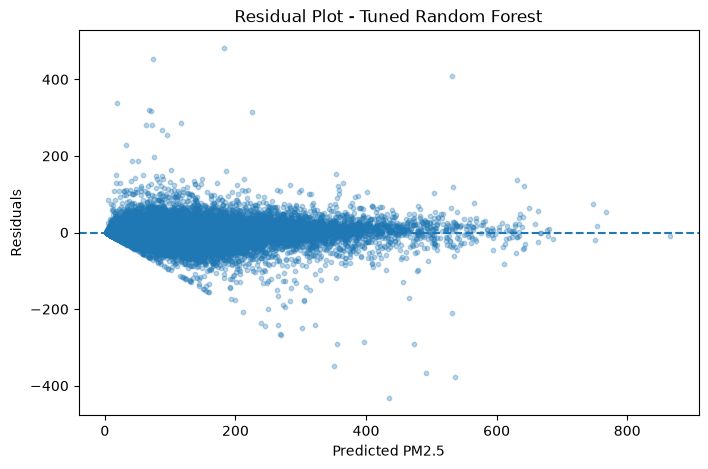

In [109]:
import matplotlib.pyplot as plt

# Calculate residuals
residuals = y_test - tuned_rf_pred

plt.figure(figsize=(8, 5))
plt.scatter(
    tuned_rf_pred,
    residuals,
    alpha=0.3,
    s=10
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel("Predicted PM2.5")
plt.ylabel("Residuals")
plt.title("Residual Plot - Tuned Random Forest")
plt.show()

### Residual Plot Observation

The residuals are mostly concentrated around the zero line, indicating that
the tuned Random Forest generally produces predictions close to the actual
PM2.5 values. However, the spread of residuals is larger for lower-to-middle
predicted values, and a few observations have relatively large positive or
negative residuals. This indicates that the model has some larger prediction
errors for certain observations.

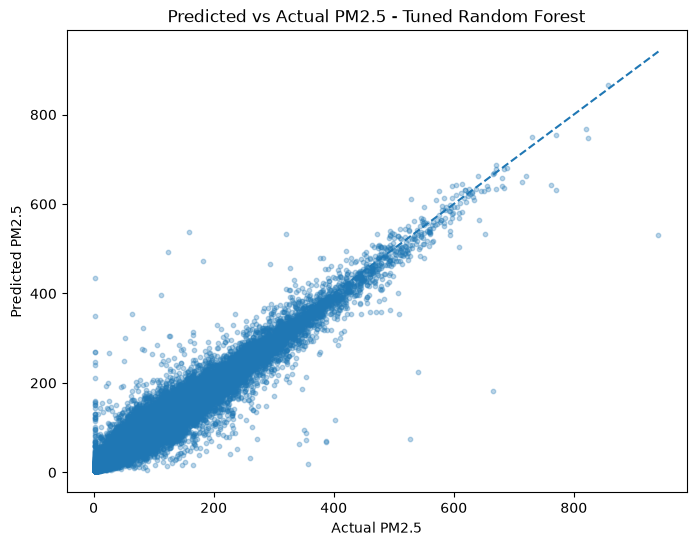

In [110]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    tuned_rf_pred,
    alpha=0.3,
    s=10
)

# Perfect prediction reference line
min_value = min(y_test.min(), tuned_rf_pred.min())
max_value = max(y_test.max(), tuned_rf_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel("Actual PM2.5")
plt.ylabel("Predicted PM2.5")
plt.title("Predicted vs Actual PM2.5 - Tuned Random Forest")

plt.show()

### Predicted vs Actual Observation

The predicted values are generally close to the actual PM2.5 values, as most
points are concentrated around the diagonal reference line representing
perfect predictions. This indicates that the tuned Random Forest provides a
strong fit to the test data. Some points are farther from the reference line,
showing that larger prediction errors occur for a smaller number of
observations.

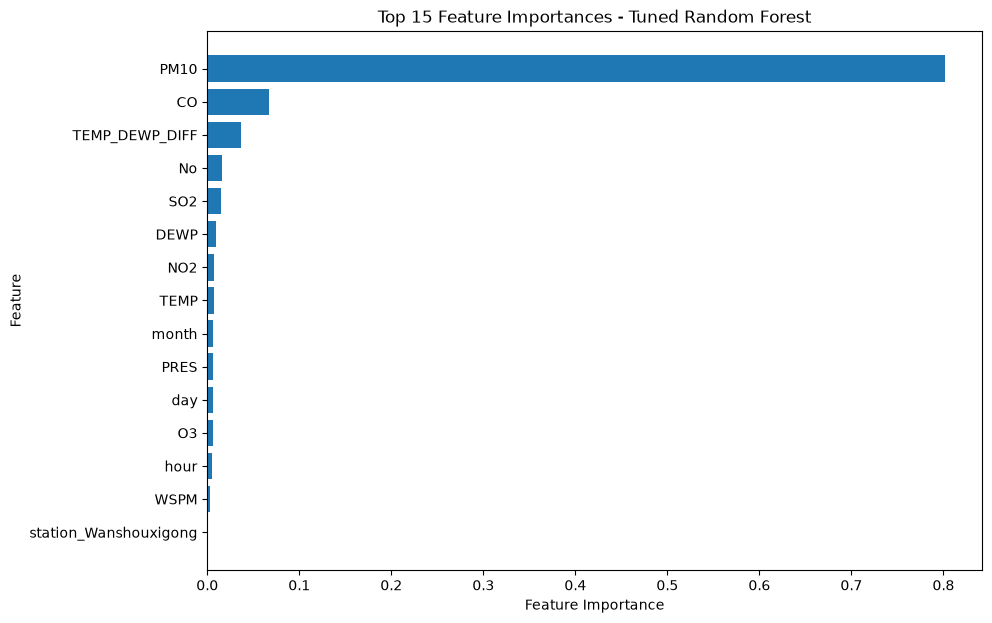

In [111]:
# Get feature names after preprocessing
feature_names = (
    numerical_features +
    list(encoder.get_feature_names_out(categorical_features))
)

# Get feature importance from the tuned Random Forest
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': tuned_rf_model.feature_importances_
})

# Sort by importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
top_features = importance_df.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'][::-1],
    top_features['Importance'][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances - Tuned Random Forest")

plt.show()

### Feature Importance Observation

The feature-importance plot shows that PM10 has the highest importance in
the tuned Random Forest model, followed by CO. The engineered feature
TEMP_DEWP_DIFF also contributes to the model's predictions. Other variables,
including SO2, DEWP, TEMP, NO2, month, O3, day, PRES, hour, WSPM, and year,
have comparatively smaller importance values among the top 15 features shown.

These importance values indicate the relative contribution of features to
the Random Forest's predictions; they do not indicate the direction of the
relationship with PM2.5.

### Sample Predictions

A sample of actual vs predicted PM2.5 values from the tuned Random Forest on the test set.

In [112]:
comparison = pd.DataFrame({
    'Actual PM2.5': y_test.values[:10],
    'Predicted PM2.5': tuned_rf_pred[:10].round(1)
})
comparison

,Actual PM2.5,Predicted PM2.5
0,3.0,3.9
1,121.0,118.3
2,97.0,86.7
3,9.0,12.2
4,94.0,90.0
5,34.0,24.5
6,81.0,102.5
7,26.0,25.2
8,83.0,141.1
9,155.0,132.2


In [113]:
from sklearn.model_selection import cross_val_score

# 5-fold cross-validation for the tuned Random Forest
rf_cv_scores = cross_val_score(
    tuned_rf_model,
    X_train_processed,
    y_train,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

print("Random Forest - 5-Fold Cross-Validation R2 Scores:")
print(rf_cv_scores)

print("\nMean CV R2:", rf_cv_scores.mean())
print("Standard Deviation:", rf_cv_scores.std())

Random Forest - 5-Fold Cross-Validation R2 Scores:
[0.95233518 0.95549969 0.95401731 0.95042029 0.95507809]

Mean CV R2: 0.9534701123887315
Standard Deviation: 0.0018758292872268368


### 5-Fold Cross-Validation

Five-fold cross-validation was performed on the two best-performing models
from the initial test-set comparison: Random Forest Regressor and
K-Nearest Neighbors Regressor. The training data was divided into five
folds, with each fold used once as the validation set while the remaining
four folds were used for training.

In [114]:
# 5-fold cross-validation for K-Nearest Neighbors

knn_cv_scores = cross_val_score(
    knn_model,
    X_train_processed,
    y_train,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

print("KNN - 5-Fold Cross-Validation R2 Scores:")
print(knn_cv_scores)

print("\nMean CV R2:", knn_cv_scores.mean())
print("Standard Deviation:", knn_cv_scores.std())

KNN - 5-Fold Cross-Validation R2 Scores:
[0.93162828 0.93385756 0.93432377 0.92992665 0.93457665]

Mean CV R2: 0.9328625827394414
Standard Deviation: 0.0018003472831024543


In [115]:
cv_summary = pd.DataFrame({
    'Model': [
        'Random Forest Regressor',
        'K-Nearest Neighbors Regressor'
    ],
    'Mean CV R2': [
        rf_cv_scores.mean(),
        knn_cv_scores.mean()
    ],
    'Std CV R2': [
        rf_cv_scores.std(),
        knn_cv_scores.std()
    ]
})

cv_summary

,Model,Mean CV R2,Std CV R2
0,Random Forest Regressor,0.953470,0.001876
1,K-Nearest Neighbors Regressor,0.932863,0.001800


### Limitations

A random split on hourly data lets neighbouring hours appear in both train and test, which
may slightly inflate R², especially for KNN and Random Forest. A time-based split would be
stricter.